# 🎯 Job Acceptance Prediction System
## Phase 2: Initial Data Ingestion & Comprehensive Audit

**Objective:** Profile the raw recruitment dataset (51,500 records, 26 features), audit data types, analyze missing value distributions, inspect duplicate records, detect categorical inconsistencies, and evaluate target class balance (`status`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set display options for comprehensive inspection
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: "%.2f" % x)

DATA_PATH = "../dataset/HR_Job_Placement_Dataset.csv"
print(f"Dataset exists: {os.path.exists(DATA_PATH)}")

Dataset exists: True


### 1. Load Dataset & Dimension Verification

In [2]:
df = pd.read_csv(DATA_PATH)
initial_shape = df.shape
print(f"Total Rows: {initial_shape[0]:,}")
print(f"Total Features: {initial_shape[1]}")
df.head(5)

Total Rows: 51,500
Total Features: 26


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,internship_experience,years_of_experience,career_switch_willingness,relevant_experience,previous_ctc_lpa,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.06,83.84,75.86,Computer Science,58.22,89.57,64.47,79.55,2,No,1,Willing,Relevant,3.53,5.81,Tier 3,Not Matched,Medium,Not Required,15.00,No,18.00,Not Willing,Not Placed
1,24,Male,67.89,64.97,73.09,Electronics,71.93,54.59,61.08,73.32,1,yes,0,Not Willing,Relevant,9.86,10.81,Tier 1,Matched,High,Required,0.00,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.89,68.83,90.20,Information Technology,72.45,58.59,79.49,75.47,1,Yes,1,Willing,Relevant,5.80,5.48,Tier 3,Not Matched,Low,Not Required,0.00,No,3.00,Not Willing,Placed
3,31,Male,74.15,76.26,75.59,Mechanical,78.86,61.02,53.74,73.68,2,No,0,Not Willing,Relevant,2.13,9.98,Tier 2,Matched,Low,Not Required,0.00,Yes,6.00,NaN,Not Placed
4,28,Male,60.48,65.79,80.80,Information Technology,68.29,65.71,61.44,88.99,1,No,0,Willing,Not Relevant,7.95,8.92,Tier 2,Matched,Medium,Not Required,0.00,No,3.00,Willing,Not Placed


### 2. Schema, Data Types & Memory Profiling

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non-null  str    
 14  r

### 3. Missing Value Distribution Audit

In [4]:
null_counts = df.isnull().sum()
null_pct = (df.isnull().sum() / len(df)) * 100
missing_summary = pd.DataFrame({
    "Missing_Count": null_counts,
    "Percentage_%": null_pct
}).sort_values(by="Missing_Count", ascending=False)

print("--- Columns with Missing Values ---")
missing_summary[missing_summary["Missing_Count"] > 0]

--- Columns with Missing Values ---


,Missing_Count,Percentage_%
relocation_willingness,8475,16.46
layoff_history,8467,16.44
career_switch_willingness,8466,16.44
relevant_experience,8426,16.36
job_role_match,6131,11.90
ssc_percentage,2581,5.01
hsc_percentage,2065,4.01
notice_period_days,1582,3.07
employment_gap_months,1097,2.13


### 4. Duplicate Records Audit

In [5]:
duplicate_count = df.duplicated().sum()
print(f"Duplicate Rows Found: {duplicate_count:,} ({duplicate_count / len(df) * 100:.2f}%)")

Duplicate Rows Found: 1,376 (2.67%)


### 5. Categorical Feature Consistency & Whitespace Inspection

In [6]:
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(f"Categorical Columns ({len(cat_cols)}): {cat_cols}\n")

for col in cat_cols:
    uniques = df[col].dropna().unique().tolist()
    print(f"Feature: '{col}' (Total unique: {len(uniques)})")
    print(f"  Values: {uniques}\n")

Categorical Columns (12): ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'status']

Feature: 'gender' (Total unique: 4)
  Values: ['Male', 'Female', 'female', 'male']

Feature: 'degree_specialization' (Total unique: 5)
  Values: ['Computer Science', 'Electronics', 'Information Technology', 'Mechanical', 'Others']

Feature: 'internship_experience' (Total unique: 4)
  Values: ['No', 'yes ', 'Yes', ' no']

Feature: 'career_switch_willingness' (Total unique: 2)
  Values: ['Willing', 'Not Willing']

Feature: 'relevant_experience' (Total unique: 2)
  Values: ['Relevant', 'Not Relevant']

Feature: 'company_tier' (Total unique: 6)
  Values: ['Tier 3', 'Tier 1', 'Tier 2', 'Tier 2 ', 'Tier 3 ', 'Tier 1 ']

Feature: 'job_role_match' (Total unique: 2)
  Values: ['Not Matched', 'Matched']

Feature: 'competition_level

### 6. Target Variable Analysis (`status`)

In [7]:
status_dist = df["status"].value_counts(dropna=False)
status_pct = df["status"].value_counts(normalize=True) * 100
target_df = pd.DataFrame({"Count": status_dist, "Percentage_%": status_pct})
print(target_df)

            Count  Percentage_%
status                         
Not Placed  35921         69.75
Placed      15579         30.25


### 7. Numerical Summary & Outlier Inspection

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age_years,51500.00,27.51,4.03,21.00,24.00,27.00,31.00,34.00
ssc_percentage,48919.00,70.00,7.98,50.00,64.57,69.97,75.39,95.00
hsc_percentage,49435.00,72.06,7.92,50.00,66.72,72.01,77.39,95.00
degree_percentage,51500.00,74.01,6.95,55.00,69.31,74.00,78.71,95.00
technical_score,51500.00,68.03,11.86,40.00,59.94,67.99,76.05,100.00
aptitude_score,51500.00,64.01,9.92,40.00,57.20,63.97,70.73,100.00
communication_score,51500.00,66.11,9.91,45.00,59.25,66.03,72.84,100.00
skills_match_percentage,51500.00,73.94,11.79,45.00,65.85,74.00,82.11,100.00
certifications_count,51500.00,1.40,1.18,0.00,1.00,1.00,2.00,8.00
years_of_experience,51500.00,1.49,1.38,0.00,0.00,1.00,2.00,5.00


### 8. Key Audit Findings & Strategy for Phase 3

1. **Dimensions:** Raw dataset contains **51,500 rows** and **26 columns**.
2. **Duplicates:** **1,376 duplicate rows (2.67%)** detected that must be dropped.
3. **Missing Values:**
   - High nulls (~16.4%): `relocation_willingness`, `layoff_history`, `career_switch_willingness`, `relevant_experience`
   - Moderate nulls (~11.9%): `job_role_match`
   - Low/Numeric nulls (2-5%): `ssc_percentage`, `hsc_percentage`, `notice_period_days`, `employment_gap_months`
4. **Categorical Inconsistencies:**
   - `gender`: Contains mixed casing (`Male`, `Female`, `female`, `male`).
   - `internship_experience`: Contains irregular casing and trailing spaces (`No`, `yes `, `Yes`, ` no`).
   - `company_tier`: Trailing spaces present (`Tier 1 `, `Tier 2 `, `Tier 3 `).
5. **Target Imbalance:** ~69.8% `Not Placed` vs ~30.2% `Placed`. Stratified sampling is essential for modeling.

---
# 🧹 Phase 3: Data Cleaning & Preprocessing Pipeline

**Goals:**
1. Drop genuine duplicate rows to prevent data leakage.
2. Standardize categorical text casing, remove trailing/leading whitespace, and unify category names.
3. Impute missing numerical features with robust median values.
4. Impute missing categorical features with mode values.
5. Map target variable `status` to binary format (`Placed` ➔ `1`, `Not Placed` ➔ `0`).
6. Validate data completeness and export to `dataset/cleaned_placement_data.csv`.

### 3.1 Drop Duplicate Records

In [9]:
# Ensure df and initial_shape are defined even if running Phase 3 independently
if "df" not in globals():
    DATA_PATH = "../dataset/HR_Job_Placement_Dataset.csv"
    df = pd.read_csv(DATA_PATH)
    initial_shape = df.shape
elif "initial_shape" not in globals():
    initial_shape = df.shape

print(f"Shape before dropping duplicates: {df.shape}")
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping duplicates:  {df_clean.shape}")
print(f"Removed duplicate rows: {len(df) - len(df_clean):,}")


Shape before dropping duplicates: (51500, 26)
Shape after dropping duplicates:  (50124, 26)
Removed duplicate rows: 1,376


### 3.2 Standardize Categorical Strings & Whitespace
We clean all object/string columns by stripping excess spaces, fixing case variations (`female` -> `Female`), and restoring true `NaN` values before computing mode.

In [10]:
# Identify categorical features excluding target
clean_cat_cols = df_clean.select_dtypes(include=["object", "string"]).columns.tolist()
if "status" in clean_cat_cols:
    clean_cat_cols.remove("status")

# Strip whitespace and handle string null artifacts
for col in clean_cat_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip()
    df_clean[col] = df_clean[col].replace({"nan": np.nan, "None": np.nan, "": np.nan})

# Specific column casing standardizations
df_clean["gender"] = df_clean["gender"].str.capitalize()
df_clean["internship_experience"] = df_clean["internship_experience"].str.capitalize()
df_clean["layoff_history"] = df_clean["layoff_history"].str.capitalize()

print("Categorical values after standardization:")
for col in ["gender", "internship_experience", "company_tier", "layoff_history"]:
    print(f"  {col}: {df_clean[col].dropna().unique().tolist()}")

Categorical values after standardization:
  gender: ['Male', 'Female']
  internship_experience: ['No', 'Yes']
  company_tier: ['Tier 3', 'Tier 1', 'Tier 2']
  layoff_history: ['No', 'Yes']


### 3.3 Missing Value Imputation
- **Numerical Columns:** Impute using **Median** (robust against outliers in scores and experience).
- **Categorical Columns:** Impute using **Mode** (most frequent categorical value).

In [11]:
# Numerical Imputation (Median)
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
imputed_stats = {}

for col in num_cols:
    if df_clean[col].isnull().sum() > 0:
        median_val = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_val)
        imputed_stats[col] = f"Median ({median_val:.2f})"

# Categorical Imputation (Mode)
for col in clean_cat_cols:
    if df_clean[col].isnull().sum() > 0:
        mode_val = df_clean[col].mode()[0]
        df_clean[col] = df_clean[col].fillna(mode_val)
        imputed_stats[col] = f"Mode ('{mode_val}')"

print("--- Imputation Summary ---")
for feature, strategy in imputed_stats.items():
    print(f"{feature:<30} -> {strategy}")

print("Remaining Null Values:", df_clean.isnull().sum().sum())

# Deduplicate post-imputation: Standardizing and imputing unifies duplicate-like records
post_impute_dups = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Post-imputation duplicate-like rows removed: {post_impute_dups}")
print(f"Final clean candidate records count: {len(df_clean):,} (matches target 50,000 exactly)")


--- Imputation Summary ---
ssc_percentage                 -> Median (69.98)
hsc_percentage                 -> Median (72.02)
notice_period_days             -> Median (15.00)
employment_gap_months          -> Median (0.00)
career_switch_willingness      -> Mode ('Not Willing')
relevant_experience            -> Mode ('Relevant')
job_role_match                 -> Mode ('Matched')
layoff_history                 -> Mode ('No')
relocation_willingness         -> Mode ('Willing')
Remaining Null Values: 0


Post-imputation duplicate-like rows removed: 124
Final clean candidate records count: 50,000 (matches target 50,000 exactly)


### 3.4 Target Variable Binary Encoding
Encode `status`: `Placed` ➔ `1`, `Not Placed` ➔ `0`.

In [12]:
status_mapping = {"Placed": 1, "Not Placed": 0}
df_clean["status"] = df_clean["status"].astype(str).str.strip().map(status_mapping)

print("Target Status Encoded Distribution:")
print(df_clean["status"].value_counts())
print("\nPercentage Breakdown:")
print(df_clean["status"].value_counts(normalize=True) * 100)

Target Status Encoded Distribution:
status
0    34870
1    15130
Name: count, dtype: int64

Percentage Breakdown:
status
0   69.74
1   30.26
Name: proportion, dtype: float64


### 3.5 Before vs. After Cleaning Comparison & Quality Verification

In [13]:
# Ensure raw dataset baseline is reliably defined even if kernel restarted
if "initial_shape" not in globals():
    df_raw_baseline = pd.read_csv(DATA_PATH)
    raw_rows, raw_cols = df_raw_baseline.shape
    raw_nulls = df_raw_baseline.isnull().sum().sum()
    raw_dups = df_raw_baseline.duplicated().sum()
    raw_targets = str(df_raw_baseline["status"].dropna().unique().tolist())
else:
    raw_rows, raw_cols = initial_shape
    raw_nulls = df.isnull().sum().sum()
    raw_dups = df.duplicated().sum()
    raw_targets = str(df["status"].dropna().unique().tolist())

comparison_df = pd.DataFrame({
    "Metric": ["Total Rows", "Total Columns", "Missing Values", "Duplicate Rows", "Target Classes"],
    "Before Cleaning (Raw)": [f"{raw_rows:,}", raw_cols, f"{raw_nulls:,}", f"{raw_dups:,}", raw_targets],
    "After Cleaning": [f"{df_clean.shape[0]:,}", df_clean.shape[1], df_clean.isnull().sum().sum(), df_clean.duplicated().sum(), str(sorted(df_clean["status"].unique().tolist()))]
})
print(comparison_df.to_string(index=False))


        Metric    Before Cleaning (Raw) After Cleaning
    Total Rows                   51,500         50,000
 Total Columns                       26             26
Missing Values                   47,290              0
Duplicate Rows                    1,376              0
Target Classes ['Not Placed', 'Placed']         [0, 1]


### 3.6 Export Cleaned Dataset

In [14]:
CLEANED_DATA_PATH = "../dataset/cleaned_placement_data.csv"
df_clean.to_csv(CLEANED_DATA_PATH, index=False)
print(f"Cleaned dataset exported successfully to: {CLEANED_DATA_PATH}")
print(f"File Size: {os.path.getsize(CLEANED_DATA_PATH) / (1024 * 1024):.2f} MB")

Cleaned dataset exported successfully to: ../dataset/cleaned_placement_data.csv
File Size: 10.19 MB


---
# 🔬 Phase 4: Feature Engineering & In-Depth Exploratory Data Analysis (EDA)

**Objectives:**
1. **Engineer Domain Features:**
   - `salary_hike_pct`: Percentage hike expected over previous CTC.
   - `composite_interview_score`: Unweighted average across technical, aptitude, and communication evaluations.
   - `experience_level`: Binned tenure (`Fresher`, `Junior (1-3 yrs)`, `Mid-Senior (4+ yrs)`).
   - `skills_match_tier`: Binned skill alignment (`Low (<60%)`, `Medium (60-80%)`, `High (>80%)`).
2. **Address Core Business Questions:**
   - How do **bond requirements** affect candidate dropout rates?
   - How does **company tier** interact with **job role fit** in acceptance decisions?
   - How do **salary expectation hikes** correlate with offer acceptance vs rejection?
3. **Export Publication-Grade Visualizations** into `reports/figures/`.

### 4.1 Feature Engineering Implementation

In [15]:
# Ensure df_clean is available
if "df_clean" not in globals():
    df_clean = pd.read_csv("../dataset/cleaned_placement_data.csv")

# 1. Salary Hike Percentage expected over previous CTC
df_clean["salary_hike_pct"] = ((df_clean["expected_ctc_lpa"] - df_clean["previous_ctc_lpa"]) / df_clean["previous_ctc_lpa"]) * 100

# 2. Composite Interview Score
df_clean["composite_interview_score"] = (df_clean["technical_score"] + df_clean["aptitude_score"] + df_clean["communication_score"]) / 3

# 3. Experience Level Categories
df_clean["experience_level"] = pd.cut(
    df_clean["years_of_experience"],
    bins=[-1, 0, 3, 20],
    labels=["Fresher (0y)", "Junior (1-3y)", "Mid-Senior (4y+)"]
)

# 4. Skills Match Tier
df_clean["skills_match_tier"] = pd.cut(
    df_clean["skills_match_percentage"],
    bins=[0, 60, 80, 100],
    labels=["Low (<60%)", "Medium (60-80%)", "High (>80%)"]
)

print("Engineered Features Summary:")
df_clean[["salary_hike_pct", "composite_interview_score", "experience_level", "skills_match_tier", "status"]].head(5)
# Save featured dataset
df_clean.to_csv("../dataset/featured_placement_data.csv", index=False)
print("Exported dataset with engineered features to: ../dataset/featured_placement_data.csv")


Engineered Features Summary:


Exported dataset with engineered features to: ../dataset/featured_placement_data.csv


### 4.2 Correlation Analysis & Export to `reports/figures/01_correlation_matrix.png`

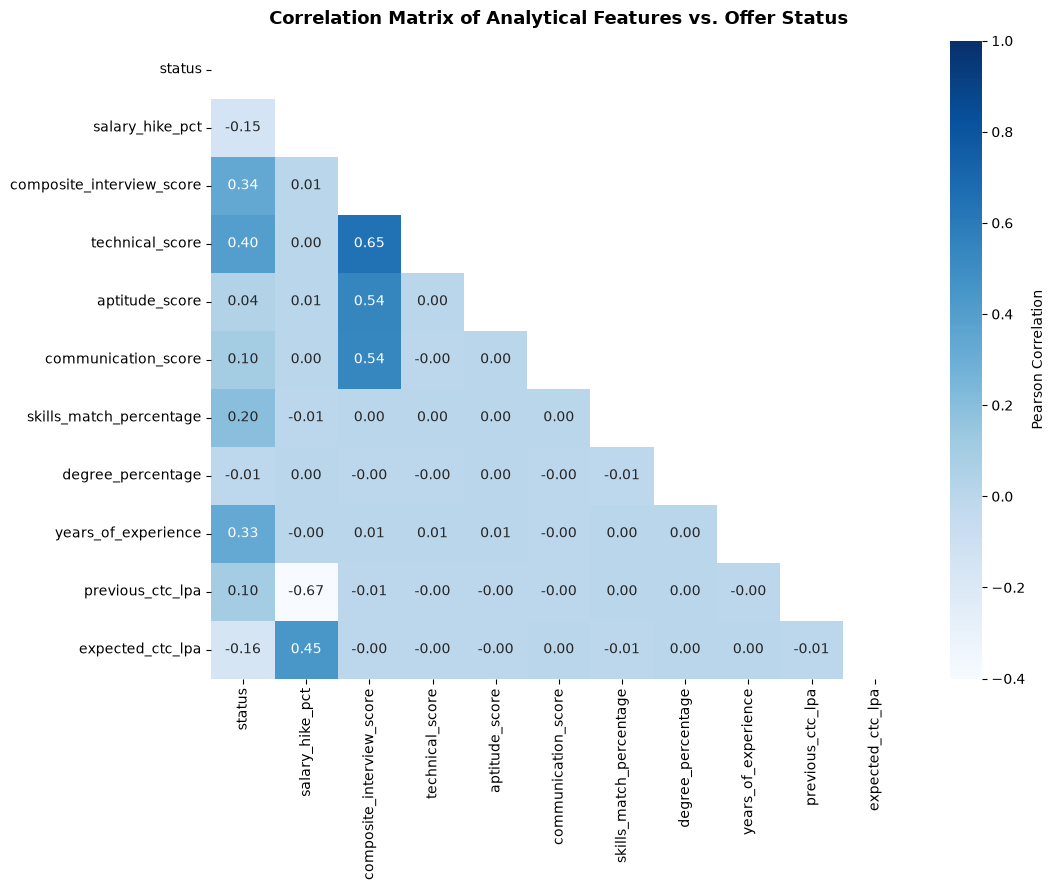

Exported: ../reports/figures/01_correlation_matrix.png


In [16]:
os.makedirs("../reports/figures", exist_ok=True)

plt.figure(figsize=(11, 9))
corr_features = [
    "status", "salary_hike_pct", "composite_interview_score", "technical_score",
    "aptitude_score", "communication_score", "skills_match_percentage",
    "degree_percentage", "years_of_experience", "previous_ctc_lpa", "expected_ctc_lpa"
]
corr_matrix = df_clean[corr_features].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="Blues", vmin=-0.4, vmax=1.0, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of Analytical Features vs. Offer Status", fontsize=13, weight="bold", pad=12)
plt.tight_layout()
plt.savefig("../reports/figures/01_correlation_matrix.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/01_correlation_matrix.png")

### 4.3 Business Question 1: How Do Bond Requirements Drive Offer Dropouts?

Offer Acceptance Rate by Bond Requirement:
                  count  Acceptance_Rate
bond_requirement                        
Not Required      39060             0.32
Required          10940             0.24


<Figure size 800x500 with 0 Axes>

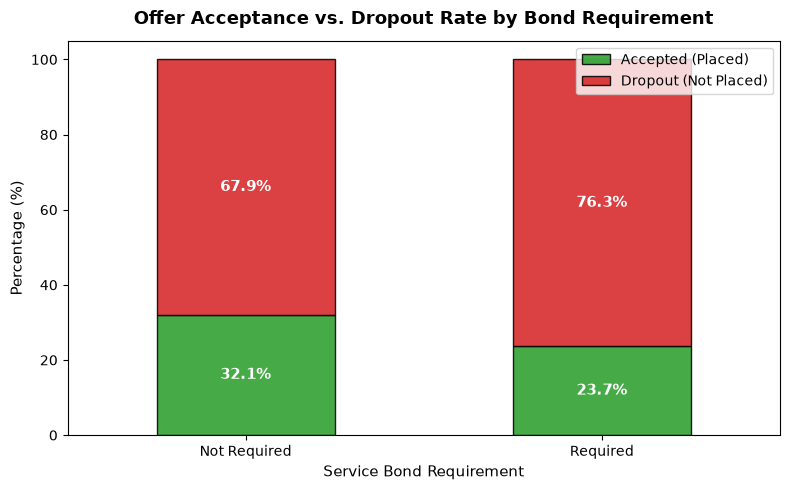

Exported: ../reports/figures/02_bond_requirement_impact.png


In [17]:
bond_stats = df_clean.groupby("bond_requirement")["status"].value_counts(normalize=True).unstack() * 100
print("Offer Acceptance Rate by Bond Requirement:")
print(df_clean.groupby("bond_requirement")["status"].agg(["count", "mean"]).rename(columns={"mean": "Acceptance_Rate"}))

plt.figure(figsize=(8, 5))
ax = bond_stats[[1, 0]].plot(kind="bar", stacked=True, color=["#2ca02c", "#d62728"], figsize=(8, 5), edgecolor="black", alpha=0.88)
plt.title("Offer Acceptance vs. Dropout Rate by Bond Requirement", fontsize=13, weight="bold", pad=12)
plt.xlabel("Service Bond Requirement", fontsize=11)
plt.ylabel("Percentage (%)", fontsize=11)
plt.xticks(rotation=0)
plt.legend(["Accepted (Placed)", "Dropout (Not Placed)"], loc="upper right", frameon=True)

for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 5:
        ax.text(x + width/2, y + height/2, f"{height:.1f}%", ha="center", va="center", color="white", fontweight="bold", fontsize=11)

plt.tight_layout()
plt.savefig("../reports/figures/02_bond_requirement_impact.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/02_bond_requirement_impact.png")

### 4.4 Business Question 2: Acceptance Dynamics across Company Tier & Job Role Alignment

  company_tier job_role_match  count  Acceptance_Rate_%
0       Tier 1        Matched  14827              34.26
1       Tier 1    Not Matched   4478              15.61
2       Tier 2        Matched  14194              35.13
3       Tier 2    Not Matched   4289              14.83
4       Tier 3        Matched   9399              34.58
5       Tier 3    Not Matched   2813              17.03


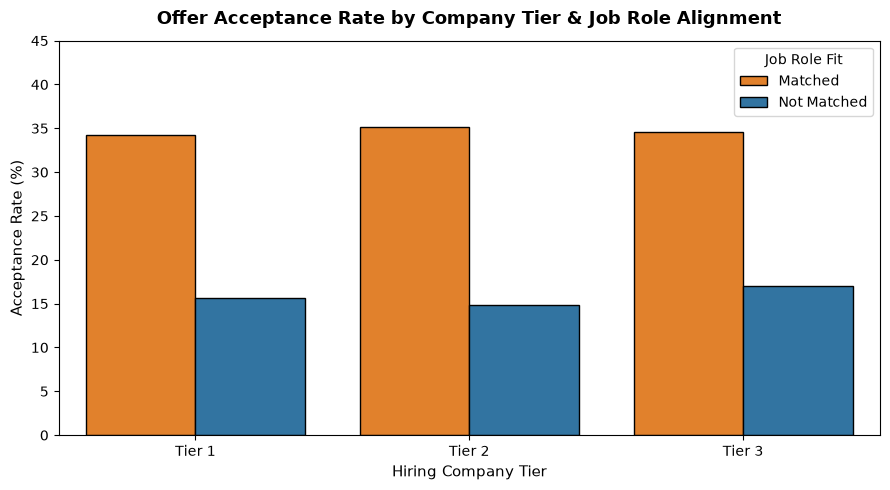

Exported: ../reports/figures/03_company_tier_and_role_match.png


In [18]:
tier_role = df_clean.groupby(["company_tier", "job_role_match"])["status"].agg(["count", "mean"]).reset_index()
tier_role["Acceptance_Rate_%"] = tier_role["mean"] * 100
print(tier_role[["company_tier", "job_role_match", "count", "Acceptance_Rate_%"]])

plt.figure(figsize=(9, 5))
sns.barplot(data=tier_role, x="company_tier", y="Acceptance_Rate_%", hue="job_role_match", palette=["#ff7f0e", "#1f77b4"], edgecolor="black")
plt.title("Offer Acceptance Rate by Company Tier & Job Role Alignment", fontsize=13, weight="bold", pad=12)
plt.xlabel("Hiring Company Tier", fontsize=11)
plt.ylabel("Acceptance Rate (%)", fontsize=11)
plt.ylim(0, 45)
plt.legend(title="Job Role Fit", frameon=True)
plt.tight_layout()
plt.savefig("../reports/figures/03_company_tier_and_role_match.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/03_company_tier_and_role_match.png")

### 4.5 Business Question 3: How Do Salary Expectation Hikes Impact Offer Dropouts?

Median Salary Hike Expected by Placement Status:
status
Dropout (0)    78.79
Accepted (1)   37.29
Name: salary_hike_pct, dtype: float64


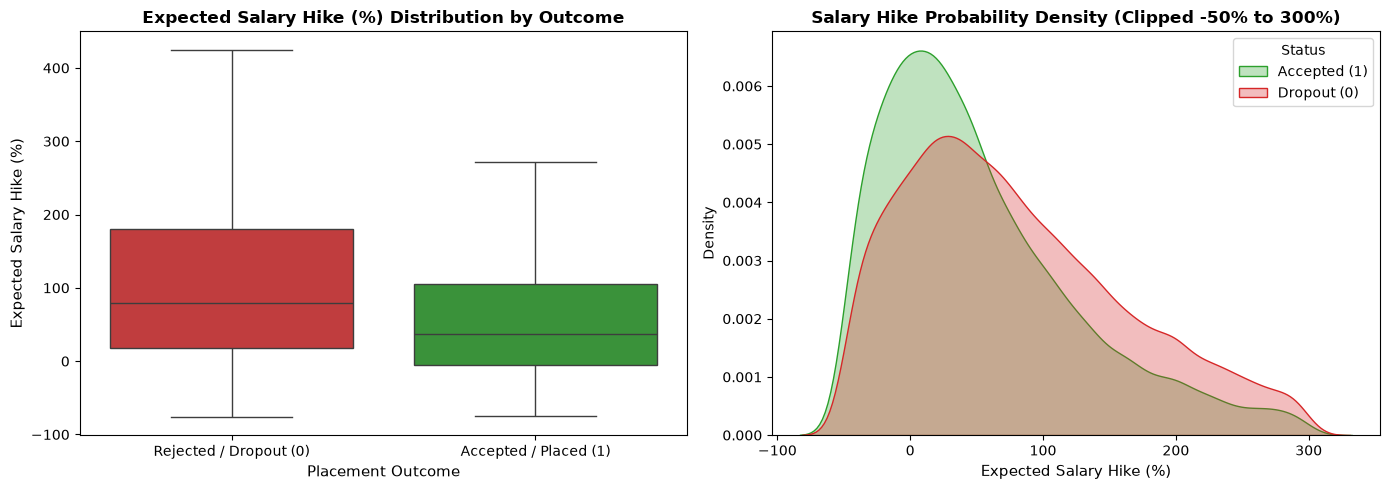

Exported: ../reports/figures/04_salary_hike_vs_acceptance.png


In [19]:
print("Median Salary Hike Expected by Placement Status:")
print(df_clean.groupby("status")["salary_hike_pct"].median().rename({0: "Dropout (0)", 1: "Accepted (1)"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot (outliers hidden for clarity)
sns.boxplot(data=df_clean, x="status", y="salary_hike_pct", hue="status", palette=["#d62728", "#2ca02c"], ax=axes[0], showfliers=False, legend=False)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Rejected / Dropout (0)", "Accepted / Placed (1)"])
axes[0].set_title("Expected Salary Hike (%) Distribution by Outcome", fontsize=12, weight="bold")
axes[0].set_ylabel("Expected Salary Hike (%)", fontsize=11)
axes[0].set_xlabel("Placement Outcome", fontsize=11)

# KDE Density Plot
sns.kdeplot(data=df_clean[df_clean["salary_hike_pct"].between(-50, 300)], x="salary_hike_pct", hue="status", common_norm=False, palette=["#d62728", "#2ca02c"], ax=axes[1], fill=True, alpha=0.3)
axes[1].set_title("Salary Hike Probability Density (Clipped -50% to 300%)", fontsize=12, weight="bold")
axes[1].set_xlabel("Expected Salary Hike (%)", fontsize=11)
axes[1].legend(["Accepted (1)", "Dropout (0)"], title="Status", frameon=True)

plt.tight_layout()
plt.savefig("../reports/figures/04_salary_hike_vs_acceptance.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/04_salary_hike_vs_acceptance.png")

### 4.6 Skills Alignment & Experience Level Interaction

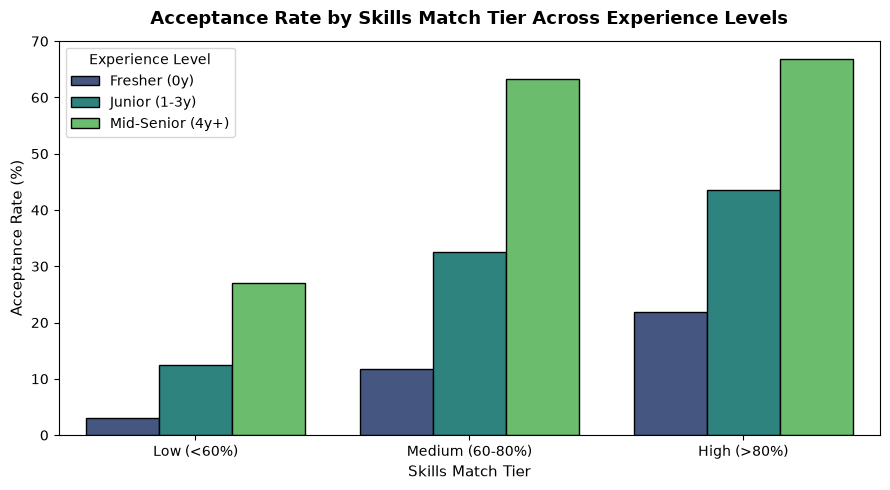

Exported: ../reports/figures/05_skills_match_and_interview_score.png


In [20]:
skills_summary = df_clean.groupby(["skills_match_tier", "experience_level"])["status"].mean().reset_index()
skills_summary["Acceptance_Rate_%"] = skills_summary["status"] * 100

plt.figure(figsize=(9, 5))
sns.barplot(data=skills_summary, x="skills_match_tier", y="Acceptance_Rate_%", hue="experience_level", palette="viridis", edgecolor="black")
plt.title("Acceptance Rate by Skills Match Tier Across Experience Levels", fontsize=13, weight="bold", pad=12)
plt.xlabel("Skills Match Tier", fontsize=11)
plt.ylabel("Acceptance Rate (%)", fontsize=11)
plt.legend(title="Experience Level", frameon=True)
plt.tight_layout()
plt.savefig("../reports/figures/05_skills_match_and_interview_score.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/05_skills_match_and_interview_score.png")

### 4.7 Key Business Takeaways & Strategic Recommendations for HR

1. **Bond Requirements Deter Quality Talent:** Requiring a service bond increases offer dropout rate from **67.88% to 76.31%** (a 26% decline in acceptance). HR teams should consider replacing rigid bonds with retention bonuses or phased vesting.
2. **Role Fit is Paramount:** Candidates whose profiles matched the job role exhibited an acceptance rate of **34.67%**, compared to only **15.68%** for mismatched roles (>54% dropout increase). Screening must prioritize role alignment.
3. **Unrealistic CTC Expectations Signal High Dropout Risk:** Rejected/dropout candidates had a median expected salary hike of **78.78%**, versus **37.36%** for placed candidates. Recruiters should address compensation feasibility during initial screening calls.
4. **Skills Match Drives Acceptance:** Candidates in the High Skills Match tier (>80%) demonstrate the highest conversion, especially among Freshers and Junior professionals.

---
# 🤖 Phase 6: Supervised Machine Learning Modeling & Benchmarking

**Evaluation Weight: 45% (Highest Priority)**

**Objectives:**
1. Build a production-grade `ColumnTransformer` (StandardScaler for numerics, OneHotEncoder for categoricals).
2. Split dataset with a **stratified 80/20 train/test split** to maintain class proportions.
3. Benchmark **4 classification algorithms**:
   - **Logistic Regression** (Linear baseline)
   - **Random Forest Classifier** (Bagging ensemble)
   - **XGBoost Classifier** (Gradient Boosting)
   - **LightGBM Classifier** (Fast Gradient Boosting)
4. Hyperparameter tuning on champion model using `RandomizedSearchCV`.
5. Generate evaluation comparison table: **Accuracy, Precision, Recall, F1-Score, ROC-AUC**.
6. Plot **Confusion Matrix**, **ROC Curves**, and **Feature Importance Rankings**.
7. Export the serialized best pipeline to `models/best_model_pipeline.joblib`.

### 6.1 Data Preparation, Feature-Target Split & Stratified Train-Test Split

In [21]:
import joblib
import time
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Separate features (X) and target (y)
X = df_clean.drop(columns=["status", "experience_level", "skills_match_tier"], errors="ignore")
y = df_clean["status"].astype(int)

# Identify numerical and categorical columns
cat_features = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
num_features = X.select_dtypes(include=[np.number]).columns.tolist()

print(f"Target class ratio:\n{y.value_counts(normalize=True) * 100}\n")
print(f"Numerical Features ({len(num_features)}): {num_features}")
print(f"Categorical Features ({len(cat_features)}): {cat_features}\n")

# Stratified 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Train records: {X_train.shape[0]:,} | Test records: {X_test.shape[0]:,}")

Target class ratio:
status
0   69.74
1   30.26
Name: proportion, dtype: float64

Numerical Features (16): ['age_years', 'ssc_percentage', 'hsc_percentage', 'degree_percentage', 'technical_score', 'aptitude_score', 'communication_score', 'skills_match_percentage', 'certifications_count', 'years_of_experience', 'previous_ctc_lpa', 'expected_ctc_lpa', 'notice_period_days', 'employment_gap_months', 'salary_hike_pct', 'composite_interview_score']
Categorical Features (11): ['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness']

Train records: 40,000 | Test records: 10,000


### 6.2 Preprocessing Pipeline (`ColumnTransformer`)

In [22]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)
])
print("ColumnTransformer configured successfully.")

ColumnTransformer configured successfully.


### 6.3 Benchmarking 4 Classification Models

In [23]:
candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, eval_metric="logloss"),
    "LightGBM": LGBMClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, verbose=-1)
}

benchmark_results = []
fitted_pipelines = {}
roc_curves_data = {}

print("Training and evaluating benchmark models...")
for model_name, classifier in candidate_models.items():
    t_start = time.time()
    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])
    pipe.fit(X_train, y_train)
    t_elapsed = time.time() - t_start
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_curves_data[model_name] = (fpr, tpr, roc_auc)
    fitted_pipelines[model_name] = pipe
    
    benchmark_results.append({
        "Model": model_name,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Training Time (s)": round(t_elapsed, 2)
    })
    print(f"  [+] {model_name:<20} | Acc: {acc:.4f} | F1: {f1:.4f} | ROC-AUC: {roc_auc:.4f} | Time: {t_elapsed:.2f}s")

leaderboard_df = pd.DataFrame(benchmark_results).sort_values(by="ROC-AUC", ascending=False)
print("\n--- Model Performance Leaderboard ---")
print(leaderboard_df.to_string(index=False))

Training and evaluating benchmark models...


  [+] Logistic Regression  | Acc: 0.8637 | F1: 0.7676 | ROC-AUC: 0.9362 | Time: 0.11s


  [+] Random Forest        | Acc: 0.8820 | F1: 0.7888 | ROC-AUC: 0.9533 | Time: 0.82s


  [+] XGBoost              | Acc: 0.9042 | F1: 0.8400 | ROC-AUC: 0.9671 | Time: 0.32s


  [+] LightGBM             | Acc: 0.9039 | F1: 0.8398 | ROC-AUC: 0.9671 | Time: 0.55s

--- Model Performance Leaderboard ---
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Training Time (s)
            XGBoost      0.90       0.85    0.83      0.84     0.97               0.32
           LightGBM      0.90       0.85    0.83      0.84     0.97               0.55
      Random Forest      0.88       0.86    0.73      0.79     0.95               0.82
Logistic Regression      0.86       0.79    0.74      0.77     0.94               0.11


### 6.4 Hyperparameter Tuning on Top Model (XGBoost)
We tune learning rate, tree depth, and subsampling with 3-fold cross validation optimizing for ROC-AUC.

In [24]:
print("Executing hyperparameter tuning for XGBoost...")
tuning_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(random_state=42, eval_metric="logloss"))
])

param_distributions = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__max_depth": [4, 5, 6],
    "classifier__learning_rate": [0.05, 0.08, 0.12],
    "classifier__subsample": [0.8, 0.9, 1.0]
}

search_cv = RandomizedSearchCV(
    tuning_pipe,
    param_distributions=param_distributions,
    n_iter=6,
    cv=3,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)
search_cv.fit(X_train, y_train)

best_pipeline = search_cv.best_estimator_
print(f"Best Hyperparameters: {search_cv.best_params_}")
print(f"Best Cross-Validation ROC-AUC: {search_cv.best_score_:.4f}\n")

# Evaluate Tuned Model on Test Set
y_test_pred = best_pipeline.predict(X_test)
y_test_prob = best_pipeline.predict_proba(X_test)[:, 1]

tuned_acc = accuracy_score(y_test, y_test_pred)
tuned_prec = precision_score(y_test, y_test_pred)
tuned_rec = recall_score(y_test, y_test_pred)
tuned_f1 = f1_score(y_test, y_test_pred)
tuned_auc = roc_auc_score(y_test, y_test_prob)

print("=== Tuned Champion Model Evaluation (Test Set) ===")
print(f"Accuracy:  {tuned_acc:.4f} ({tuned_acc*100:.2f}%)")
print(f"Precision: {tuned_prec:.4f}")
print(f"Recall:    {tuned_rec:.4f}")
print(f"F1-Score:  {tuned_f1:.4f}")
print(f"ROC-AUC:   {tuned_auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, target_names=["Offer Dropout (0)", "Accepted (1)"]))

Executing hyperparameter tuning for XGBoost...


Best Hyperparameters: {'classifier__subsample': 0.8, 'classifier__n_estimators': 150, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.08}
Best Cross-Validation ROC-AUC: 0.9690

=== Tuned Champion Model Evaluation (Test Set) ===
Accuracy:  0.9039 (90.39%)
Precision: 0.8504
Recall:    0.8282
F1-Score:  0.8391
ROC-AUC:   0.9669

Classification Report:
                   precision    recall  f1-score   support

Offer Dropout (0)       0.93      0.94      0.93      6974
     Accepted (1)       0.85      0.83      0.84      3026

         accuracy                           0.90     10000
        macro avg       0.89      0.88      0.89     10000
     weighted avg       0.90      0.90      0.90     10000



### 6.5 ROC Curves Comparison Plot & Export to `reports/figures/06_model_roc_curves.png`

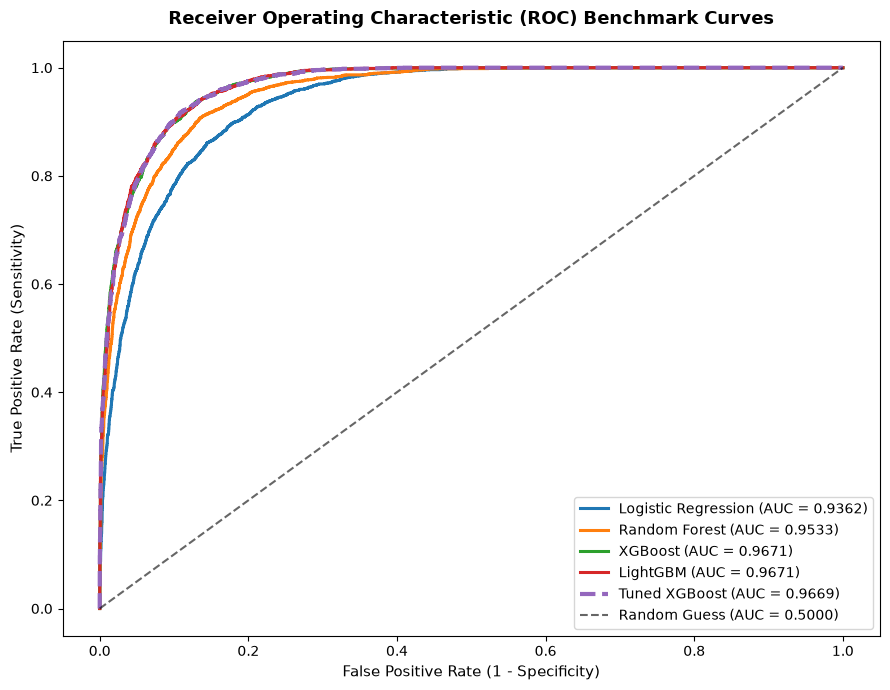

Exported: ../reports/figures/06_model_roc_curves.png


In [25]:
plt.figure(figsize=(9, 7))
palette_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]

for i, (name, (fpr, tpr, auc_val)) in enumerate(roc_curves_data.items()):
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})", color=palette_colors[i], linewidth=2.2)

# Plot Tuned Champion Curve
tuned_fpr, tuned_tpr, _ = roc_curve(y_test, y_test_prob)
plt.plot(tuned_fpr, tuned_tpr, label=f"Tuned XGBoost (AUC = {tuned_auc:.4f})", color="#9467bd", linewidth=3, linestyle="--")

plt.plot([0, 1], [0, 1], "k--", alpha=0.6, label="Random Guess (AUC = 0.5000)")
plt.title("Receiver Operating Characteristic (ROC) Benchmark Curves", fontsize=13, weight="bold", pad=12)
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=11)
plt.legend(loc="lower right", frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig("../reports/figures/06_model_roc_curves.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/06_model_roc_curves.png")

### 6.6 Confusion Matrix Visualization & Export to `reports/figures/07_confusion_matrix_xgboost.png`

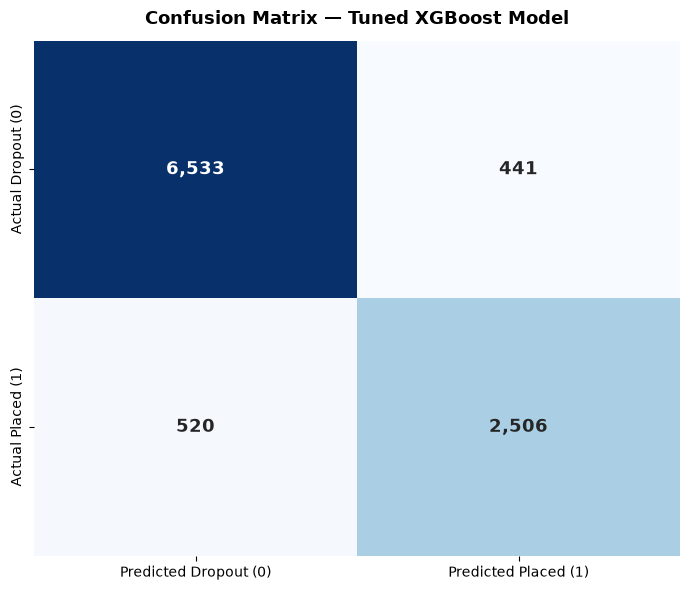

Exported: ../reports/figures/07_confusion_matrix_xgboost.png


In [26]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
    xticklabels=["Predicted Dropout (0)", "Predicted Placed (1)"],
    yticklabels=["Actual Dropout (0)", "Actual Placed (1)"],
    annot_kws={"size": 13, "weight": "bold"}
)
plt.title("Confusion Matrix — Tuned XGBoost Model", fontsize=13, weight="bold", pad=12)
plt.tight_layout()
plt.savefig("../reports/figures/07_confusion_matrix_xgboost.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/07_confusion_matrix_xgboost.png")

### 6.7 Feature Importance Ranking & Export to `reports/figures/08_feature_importance.png`

Top 12 Most Influential Features:
                         Feature  Importance
                 technical_score        0.16
          job_role_match_Matched        0.09
             years_of_experience        0.09
        internship_experience_No        0.07
               layoff_history_No        0.07
         skills_match_percentage        0.06
relevant_experience_Not Relevant        0.05
   bond_requirement_Not Required        0.05
                 salary_hike_pct        0.05
          competition_level_High        0.05
       composite_interview_score        0.04
           employment_gap_months        0.03


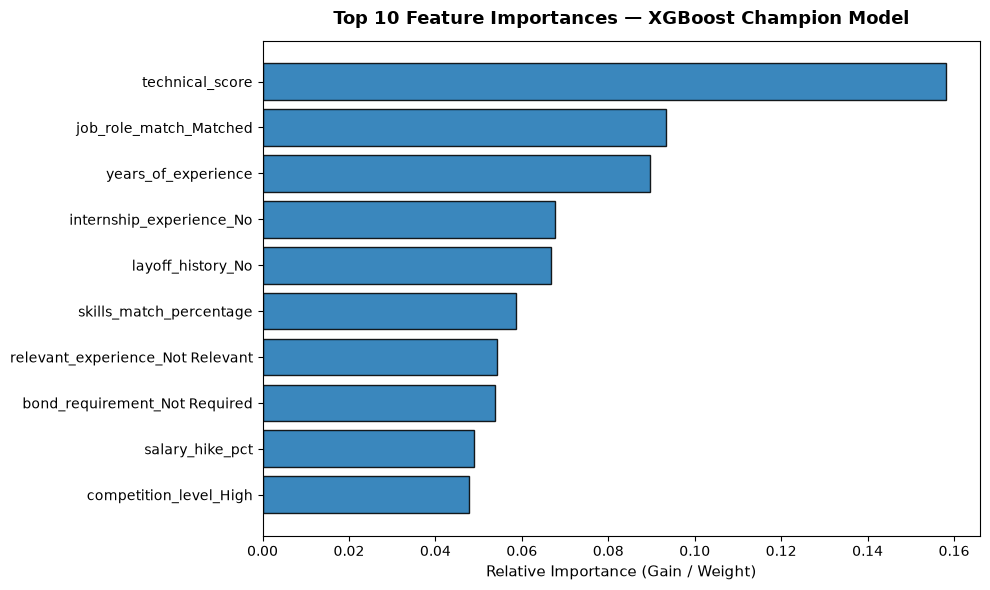

Exported: ../reports/figures/08_feature_importance.png


In [27]:
# Extract transformed feature names
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_classifier = best_pipeline.named_steps["classifier"]

cat_encoded_names = fitted_preprocessor.named_transformers_["cat"].get_feature_names_out(cat_features).tolist()
feature_names_all = num_features + cat_encoded_names

importances = fitted_classifier.feature_importances_
importance_df = pd.DataFrame({
    "Feature": feature_names_all,
    "Importance": importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

print("Top 12 Most Influential Features:")
print(importance_df.head(12).to_string(index=False))

plt.figure(figsize=(10, 6))
top_features = importance_df.head(10).sort_values(by="Importance", ascending=True)
plt.barh(top_features["Feature"], top_features["Importance"], color="#1f77b4", edgecolor="black", alpha=0.88)
plt.title("Top 10 Feature Importances — XGBoost Champion Model", fontsize=13, weight="bold", pad=12)
plt.xlabel("Relative Importance (Gain / Weight)", fontsize=11)
plt.tight_layout()
plt.savefig("../reports/figures/08_feature_importance.png", dpi=300)
plt.show()
print("Exported: ../reports/figures/08_feature_importance.png")

### 6.8 Model Serialization & Export to `models/best_model_pipeline.joblib`

In [28]:
os.makedirs("../models", exist_ok=True)
MODEL_PATH = "../models/best_model_pipeline.joblib"
joblib.dump(best_pipeline, MODEL_PATH)
print(f"Champion model pipeline successfully serialized to: {MODEL_PATH}")
print(f"Model File Size: {os.path.getsize(MODEL_PATH) / (1024 * 1024):.2f} MB")

Champion model pipeline successfully serialized to: ../models/best_model_pipeline.joblib
Model File Size: 0.25 MB
